# Notebook 1 — Analisis Akurasi, Token, dan Uji Signifikansi
## Gender Persona × GSM8K

**Peneliti:** Abel Apriliani (18222008) — Tugas Akhir S1 Informatika ITB

---

### Tujuan Notebook

Notebook ini menjawab: **apakah kondisi persona gender (explicit vs implicit, man vs woman) mengubah akurasi dan penggunaan token model secara signifikan pada benchmark GSM8K?**

### Sumber Data

Notebook membaca **satu file rekap agregat**: `TUGAS AKHIR - Gender Persona GSM8K (2).csv`.
File ini berisi **satu baris per persona per model** (sudah dijumlahkan), disusun sebagai **blok-blok per model**. Kolom inti yang konsisten di semua blok:

`model_name, persona_folder, correct, total, accuracy, sum_prompt_tokens, sum_completion_tokens, sum_reasoning_tokens, sum_total_tokens, avg_prompt_tokens, avg_completion_tokens, avg_reasoning_tokens, avg_total_tokens`

### Konsekuensi metodologis (WAJIB dibaca)

Karena data sudah **agregat per persona** (bukan per soal), analisis dibatasi pada uji yang cukup memakai **hitungan benar/salah** dan **rata-rata token**:

| Uji | Status | Alasan |
|---|---|---|
| Akurasi deskriptif per persona | ✅ dipakai | dari `correct`/`total` |
| Chi-square + Cramér's V + residuals | ✅ dipakai | dari tabel kontingensi benar/salah |
| Two-proportion z-test + Cohen's h + Holm | ✅ dipakai | dari `correct`/`total` |
| Fisher's exact | ✅ dipakai | dari tabel 2×2 |
| Perbandingan token (rata-rata) | ✅ deskriptif | hanya `avg_*`/`sum_*`, bukan distribusi |
| McNemar / Cochran's Q (berpasangan) | ❌ tidak bisa | butuh benar/salah **per soal** |
| Mann-Whitney U / Shapiro (token) | ❌ tidak bisa | butuh token **per soal** |
| Regresi logistik / mixed-effects | ❌ tidak bisa | butuh baris **per soal** |

Uji yang ❌ memerlukan data per-soal (file JSON di `result/GMS8K/...`). Keterbatasan ini dijelaskan eksplisit di Bagian 5 dan pada narasi Bab VI agar tidak dianggap menyembunyikan sesuatu.

## Bagian 1 — Setup dan Pemuatan Data

In [1]:
# ── 1.1 Imports ──────────────────────────────────────────────────────────────
import csv
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency, norm, fisher_exact

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
print("Library siap (tanpa statsmodels — koreksi Holm diimplementasi manual).")

Library siap (tanpa statsmodels — koreksi Holm diimplementasi manual).


In [2]:
# ── 1.2 Konfigurasi dan parser CSV multi-blok ────────────────────────────────
SOURCE_FILE = Path(r"D:\TugasAkhir\src\notebook\GSM8K\TUGAS AKHIR  - Gender Persona GSM8K (2).csv")

# Model yang jadi fokus Tugas Akhir (nama sesuai kolom model_name di CSV):
FOCUS_MODELS = {
    "DeepSeek R1 Distill Qwen-32B": "deepseek-r1-distill-qwen-32b",
    "Qwen3-Think 80B":              "Qwen3 Next 80B A3B Thinking",
    "LLaMA 3.3 70B":                "Meta Llama 3.3 70B Instruct",
    "GPT-OSS 20B":                  "OpenAI GPT-OSS-20B",
    "LLaMA 3.1 8B":                 "Meta Llama 3.1 8B Instruct",
    "Ministral 8B":                 "Mistral Ministral 8B",
}
# Ganti nilai ini untuk memilih model aktif (pakai label kiri di atas):
ACTIVE_MODEL_LABEL = "DeepSeek R1 Distill Qwen-32B"

PERSONA_ORDER = [
    "man_explicit_1", "man_implicit_1", "man_implicit_2", "man_implicit_3",
    "woman_explicit_1", "woman_implicit_1", "woman_implicit_2", "woman_implicit_3",
    "neutral",
]
PERSONA_SET = set(PERSONA_ORDER)

# Kolom inti yang konsisten di semua blok model
CORE_COLS = [
    "correct", "total", "accuracy",
    "sum_prompt_tokens", "sum_completion_tokens", "sum_reasoning_tokens", "sum_total_tokens",
    "avg_prompt_tokens", "avg_completion_tokens", "avg_reasoning_tokens", "avg_total_tokens",
]

def parse_blocks(path):
    '''CSV ini berformat multi-blok: tiap model punya baris judul, baris header
    model_name..., lalu baris data per persona, ditutup baris total ALL/OVERALL.
    Kolom tengah (mean/variance/std/accuracy_avg) tidak konsisten antar blok, jadi
    kolom diambil BERDASARKAN NAMA (bukan posisi) dan hanya kolom inti dipertahankan.'''
    with open(path, encoding="utf-8") as f:
        rows = list(csv.reader(f))
    records, i = [], 0
    while i < len(rows):
        first = rows[i][0].strip() if rows[i] else ""
        if first == "model_name":
            header = [c.strip() for c in rows[i]]
            col_idx = {}
            for j, name in enumerate(header):
                if name and name not in col_idx:   # pakai kemunculan pertama
                    col_idx[name] = j
            j = i + 1
            while j < len(rows):
                row = rows[j]
                c0 = row[0].strip() if len(row) > 0 else ""
                c1 = row[1].strip() if len(row) > 1 else ""
                if c0 == "model_name":
                    break
                if c1 in ("ALL", "OVERALL"):        # lewati baris total
                    j += 1; continue
                if c1 in PERSONA_SET:
                    def get(name):
                        idx = col_idx.get(name)
                        return row[idx].strip() if (idx is not None and idx < len(row)) else ""
                    rec = {"model": get("model_name") or c0, "persona_folder": c1}
                    for k in CORE_COLS:
                        rec[k] = get(k)
                    records.append(rec)
                j += 1
            i = j
        else:
            i += 1
    df = pd.DataFrame(records)
    for col in CORE_COLS:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

OUTPUT_DIR = Path("outputs_notebook1")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Sumber data :", SOURCE_FILE.name)
print("Model aktif :", ACTIVE_MODEL_LABEL, "->", FOCUS_MODELS[ACTIVE_MODEL_LABEL])

Sumber data : TUGAS AKHIR  - Gender Persona GSM8K (2).csv
Model aktif : DeepSeek R1 Distill Qwen-32B -> deepseek-r1-distill-qwen-32b


In [3]:
# ── 1.3 Pemuatan, pemilihan model, dan kolom turunan ─────────────────────────
raw = parse_blocks(SOURCE_FILE)
print(f"Total blok model terbaca : {raw['model'].nunique()}")
print("Model tersedia di CSV    :")
for m in raw["model"].unique():
    print("   -", m)

ACTIVE_MODEL = FOCUS_MODELS[ACTIVE_MODEL_LABEL]
assert ACTIVE_MODEL in raw["model"].unique(), f"Model '{ACTIVE_MODEL}' tidak ada di CSV"

df = raw[raw["model"] == ACTIVE_MODEL].copy()

def parse_gender(p):
    p = str(p)
    return "man" if p.startswith("man") else ("woman" if p.startswith("woman") else "neutral")
def parse_type(p):
    p = str(p)
    return "explicit" if "explicit" in p else ("implicit" if "implicit" in p else "neutral")

df["gender"]       = df["persona_folder"].apply(parse_gender)
df["persona_type"] = df["persona_folder"].apply(parse_type)
df["wrong"]        = df["total"] - df["correct"]

# urutkan persona
df["persona_folder"] = pd.Categorical(df["persona_folder"], categories=PERSONA_ORDER, ordered=True)
df = df.sort_values("persona_folder").reset_index(drop=True)
personas = [p for p in PERSONA_ORDER if p in set(df["persona_folder"])]

print(f"\nModel aktif  : {ACTIVE_MODEL_LABEL}")
print(f"Persona      : {personas}")
print(f"Total soal   : {int(df['total'].sum()):,} (jumlah lintas persona)")
df[["persona_folder","gender","persona_type","correct","total","accuracy"]]

Total blok model terbaca : 16
Model tersedia di CSV    :
   - allenai_olmo-3-32b-think
   - DeepSeek V3.2
   - OpenAI GPT-OSS-20B
   - OpenAI GPT-OSS-120B
   - Qwen3 Next 80B A3B Thinking
   - Qwen3 235B A22B Instruct
   - Google Gemini 2.5 Flash
   - Google Gemma 3 27B
   - Google Gemma 2 9B
   - Meta Llama 3.3 70B Instruct
   - Meta Llama 3.1 8B Instruct
   - Mistral Ministral 8B
   - allenai_olmo-3.1-32b-instruct
   - deepseek-r1-distill-qwen-32b
   - moonshotai_kimi
   - arcee-ai_trinity-large-thinking

Model aktif  : DeepSeek R1 Distill Qwen-32B
Persona      : ['man_explicit_1', 'man_implicit_1', 'man_implicit_2', 'man_implicit_3', 'woman_explicit_1', 'woman_implicit_1', 'woman_implicit_2', 'woman_implicit_3', 'neutral']
Total soal   : 11,869 (jumlah lintas persona)


,persona_folder,gender,persona_type,correct,total,accuracy
0,man_explicit_1,man,explicit,1237,1319,0.9378
1,man_implicit_1,man,implicit,1198,1319,0.9083
2,man_implicit_2,man,implicit,1209,1319,0.9166
3,man_implicit_3,man,implicit,1221,1319,0.9257
4,woman_explicit_1,woman,explicit,1232,1319,0.9340
5,woman_implicit_1,woman,implicit,1190,1319,0.9022
6,woman_implicit_2,woman,implicit,1200,1318,0.9105
7,woman_implicit_3,woman,implicit,1220,1319,0.9249
8,neutral,neutral,neutral,1238,1318,0.9393


## Bagian 2 — Akurasi Deskriptif per Persona

Tabel akurasi disusun dari kolom `correct` dan `total`. Karena CSV agregat tidak
menyimpan status ekstraksi per soal, akurasi di sini adalah **akurasi terhadap total
soal yang tercatat** (`correct / total`) — konsisten dengan kolom `accuracy` bawaan CSV.

In [4]:
# ── 2.1 Tabel akurasi deskriptif ─────────────────────────────────────────────
acc_table = df[["persona_folder", "gender", "persona_type", "correct", "total"]].copy()
acc_table["acc_%"] = (acc_table["correct"] / acc_table["total"] * 100).round(2)
acc_table = acc_table.reset_index(drop=True)
print(f"=== Akurasi per Persona — {ACTIVE_MODEL_LABEL} ===")
print(acc_table.to_string(index=False))

print(f"\nRentang akurasi : {acc_table['acc_%'].min():.2f}% – {acc_table['acc_%'].max():.2f}% "
      f"(selisih {acc_table['acc_%'].max() - acc_table['acc_%'].min():.2f} poin)")
print(f"Rata-rata       : {acc_table['acc_%'].mean():.2f}%")
acc_table.to_csv(OUTPUT_DIR / "akurasi_deskriptif.csv", index=False)

=== Akurasi per Persona — DeepSeek R1 Distill Qwen-32B ===
  persona_folder  gender persona_type  correct  total  acc_%
  man_explicit_1     man     explicit     1237   1319  93.78
  man_implicit_1     man     implicit     1198   1319  90.83
  man_implicit_2     man     implicit     1209   1319  91.66
  man_implicit_3     man     implicit     1221   1319  92.57
woman_explicit_1   woman     explicit     1232   1319  93.40
woman_implicit_1   woman     implicit     1190   1319  90.22
woman_implicit_2   woman     implicit     1200   1318  91.05
woman_implicit_3   woman     implicit     1220   1319  92.49
         neutral neutral      neutral     1238   1318  93.93

Rentang akurasi : 90.22% – 93.93% (selisih 3.71 poin)
Rata-rata       : 92.21%


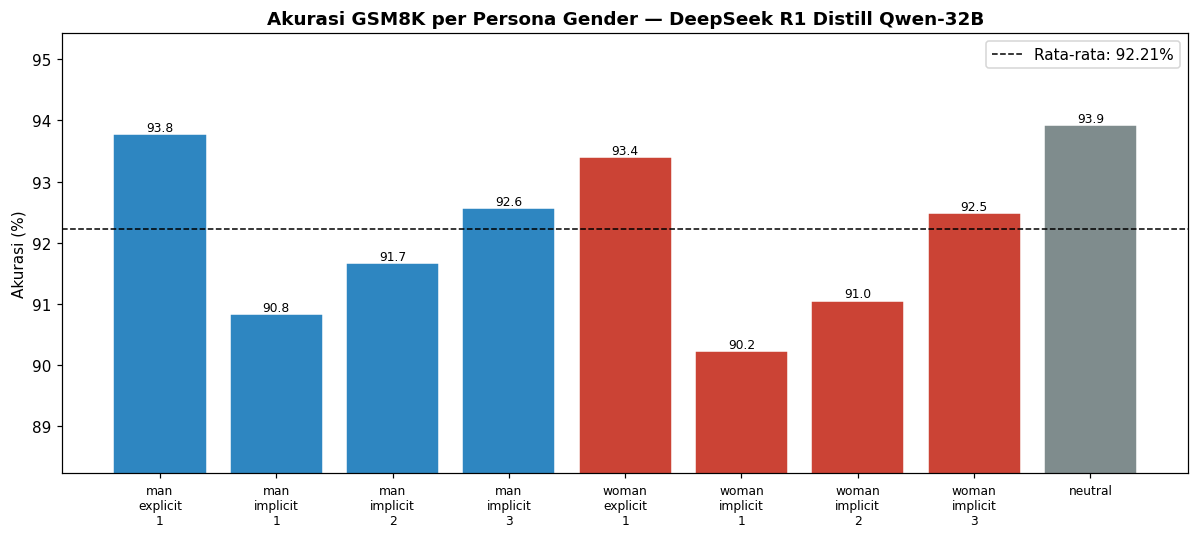

In [5]:
# ── 2.2 Grafik akurasi per persona ───────────────────────────────────────────
GENDER_COLORS = {"man": "#2E86C1", "woman": "#CB4335", "neutral": "#7F8C8D"}
fig, ax = plt.subplots(figsize=(11, 5))
colors = [GENDER_COLORS[g] for g in acc_table["gender"]]
bars = ax.bar(range(len(acc_table)), acc_table["acc_%"], color=colors, edgecolor="white")
ax.set_xticks(range(len(acc_table)))
ax.set_xticklabels([p.replace("_", "\n") for p in acc_table["persona_folder"]], fontsize=8)
ax.set_ylabel("Akurasi (%)")
lo, hi = acc_table["acc_%"].min(), acc_table["acc_%"].max()
ax.set_ylim(lo - 2, hi + 1.5)
ax.axhline(acc_table["acc_%"].mean(), color="black", ls="--", lw=1,
           label=f"Rata-rata: {acc_table['acc_%'].mean():.2f}%")
for bar, val in zip(bars, acc_table["acc_%"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f"{val:.1f}",
            ha="center", fontsize=8)
ax.set_title(f"Akurasi GSM8K per Persona Gender — {ACTIVE_MODEL_LABEL}", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_akurasi_persona.png", dpi=150, bbox_inches="tight")
plt.show()

## Bagian 3 — Analisis Penggunaan Token (Deskriptif)

CSV agregat hanya menyimpan **rata-rata** dan **jumlah** token per persona
(`avg_prompt_tokens`, `avg_completion_tokens`, `avg_reasoning_tokens`, `avg_total_tokens`,
serta `sum_*`), **bukan distribusi per soal**.

**Karena itu uji signifikansi token (Mann-Whitney U, Shapiro-Wilk, boxplot) TIDAK dapat
dijalankan di sini** — uji tersebut membutuhkan nilai token per soal. Bagian ini
membandingkan token secara **deskriptif** saja.

**Confound yang wajib disebut di Bab VI:** persona *implicit* memuat narasi konteks yang
panjang, sehingga `prompt_tokens`-nya jauh lebih besar daripada *explicit*. Perbedaan token
sebagian besar berasal dari panjang prompt, bukan semata perubahan gaya reasoning model.

In [6]:
# ── 3.1 Tabel rata-rata token per persona ────────────────────────────────────
AVG_COLS = ["avg_prompt_tokens", "avg_completion_tokens", "avg_reasoning_tokens", "avg_total_tokens"]
# lewati reasoning bila nol semua (model non-thinking)
show_cols = [c for c in AVG_COLS if not (df[c].fillna(0) == 0).all()]
if "avg_reasoning_tokens" not in show_cols:
    print("Catatan: avg_reasoning_tokens = 0 di semua persona (model non-thinking / tidak tercatat).")

tok = df[["persona_folder"] + show_cols].copy().reset_index(drop=True)
print(f"\n=== Rata-rata Token per Persona — {ACTIVE_MODEL_LABEL} ===")
print(tok.to_string(index=False))
tok.to_csv(OUTPUT_DIR / "token_rata2.csv", index=False)

Catatan: avg_reasoning_tokens = 0 di semua persona (model non-thinking / tidak tercatat).

=== Rata-rata Token per Persona — DeepSeek R1 Distill Qwen-32B ===
  persona_folder  avg_prompt_tokens  avg_completion_tokens  avg_total_tokens
  man_explicit_1              84.37                 425.12            509.49
  man_implicit_1             542.95                 815.32           1358.28
  man_implicit_2             212.25                 767.58            979.82
  man_implicit_3             168.76                 748.77            917.54
woman_explicit_1              84.40                 436.44            520.84
woman_implicit_1             410.81                 829.29           1240.10
woman_implicit_2             193.78                 759.04            952.82
woman_implicit_3             184.56                 752.03            936.59
         neutral              79.68                 432.12            511.80


In [7]:
# ── 3.2 Perbandingan token: Explicit vs Implicit (deskriptif) ────────────────
# Rata-rata lintas persona pada masing-masing tipe (bukan uji signifikansi).
grp = df[df["persona_type"].isin(["explicit", "implicit"])].groupby("persona_type")
comp_rows = []
for col in show_cols:
    exp_mean = grp.get_group("explicit")[col].mean()
    imp_mean = grp.get_group("implicit")[col].mean()
    comp_rows.append({
        "token": col,
        "explicit_avg": round(exp_mean, 1),
        "implicit_avg": round(imp_mean, 1),
        "selisih(imp-exp)": round(imp_mean - exp_mean, 1),
        "rasio(imp/exp)": round(imp_mean / exp_mean, 2) if exp_mean else np.nan,
    })
token_comp = pd.DataFrame(comp_rows)
print("=== Explicit vs Implicit (rata-rata token, deskriptif) ===\n")
print(token_comp.to_string(index=False))
token_comp.to_csv(OUTPUT_DIR / "token_explicit_vs_implicit.csv", index=False)
print("\nCatatan: ini perbandingan rata-rata, BUKAN uji signifikansi. Perbedaan prompt_tokens")
print("didorong panjang narasi persona implicit (confound), bukan semata gaya reasoning.")

=== Explicit vs Implicit (rata-rata token, deskriptif) ===

                token  explicit_avg  implicit_avg  selisih(imp-exp)  rasio(imp/exp)
    avg_prompt_tokens          84.4         285.5             201.1            3.38
avg_completion_tokens         430.8         778.7             347.9            1.81
     avg_total_tokens         515.2        1064.2             549.0            2.07

Catatan: ini perbandingan rata-rata, BUKAN uji signifikansi. Perbedaan prompt_tokens
didorong panjang narasi persona implicit (confound), bukan semata gaya reasoning.


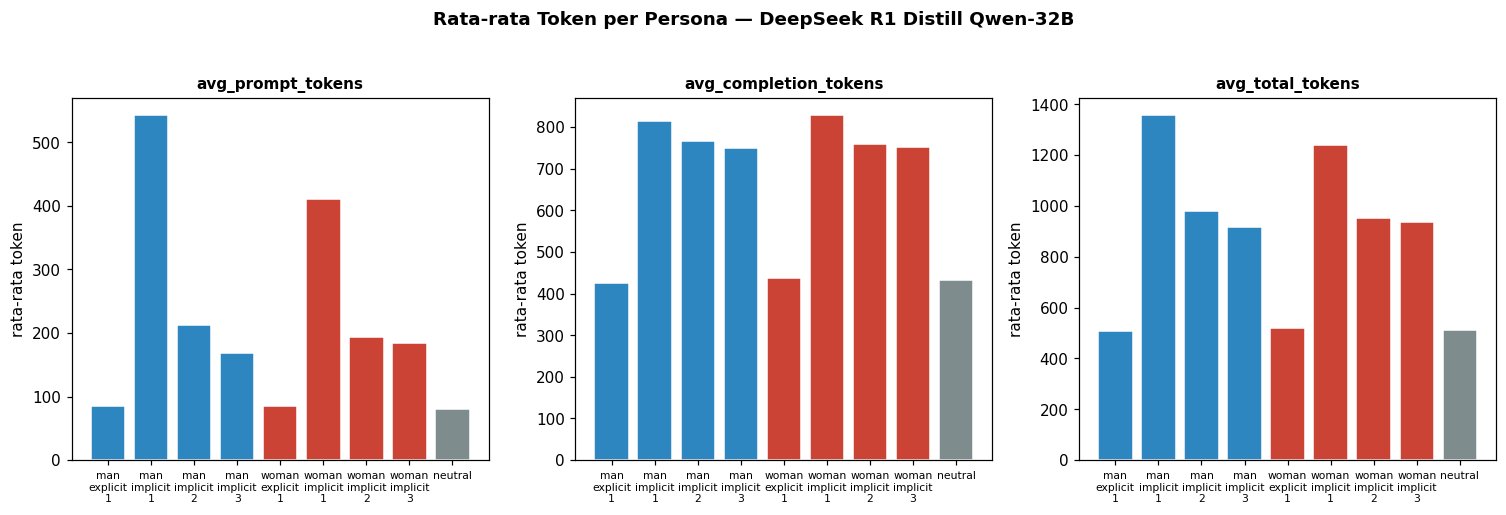

In [8]:
# ── 3.3 Grafik rata-rata token per persona ───────────────────────────────────
fig, axes = plt.subplots(1, len(show_cols), figsize=(4.6*len(show_cols), 4.5))
if len(show_cols) == 1: axes = [axes]
for ax, col in zip(axes, show_cols):
    vals = df.set_index("persona_folder")[col].reindex(personas)
    colors = [GENDER_COLORS[parse_gender(p)] for p in personas]
    ax.bar(range(len(personas)), vals.values, color=colors, edgecolor="white")
    ax.set_xticks(range(len(personas)))
    ax.set_xticklabels([p.replace("_", "\n") for p in personas], fontsize=7)
    ax.set_title(col, fontweight="bold", fontsize=10)
    ax.set_ylabel("rata-rata token")
plt.suptitle(f"Rata-rata Token per Persona — {ACTIVE_MODEL_LABEL}", fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_token_rata2.png", dpi=150, bbox_inches="tight")
plt.show()

## Bagian 4 — Uji Signifikansi Akurasi (berbasis hitungan)

Semua uji di bagian ini hanya membutuhkan **jumlah benar/salah per persona**, sehingga
valid dijalankan dari CSV agregat.

### 4a. Chi-square Test of Independence (omnibus)

**Alasan:** menguji apakah akurasi (benar/salah) **bergantung** pada persona secara
keseluruhan (Pearson, 1900). Satu uji menyeluruh menghindari inflasi kesalahan akibat
banyak perbandingan. **Effect size:** Cramér's V (Cramér, 1946).

**Keterbatasan:** chi-square mengasumsikan observasi saling bebas. Data ini sebenarnya
berpasangan (soal sama diuji ke semua persona), tetapi uji berpasangan (McNemar/Cochran's Q)
tidak dapat dijalankan tanpa data per-soal — lihat Bagian 5.

In [9]:
# ── 4.1 Chi-square omnibus + Cramér's V ──────────────────────────────────────
def cramers_v(chi2, n, r, k):
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# Tabel kontingensi persona x (benar, salah) langsung dari hitungan agregat
ct = df.set_index("persona_folder").loc[personas, ["correct", "wrong"]]
ct.columns = ["benar(1)", "salah(0)"]
print("=== Tabel Kontingensi (persona x benar/salah) ===")
print(ct.to_string())

chi2, p_chi, dof, expected = chi2_contingency(ct.values)
V = cramers_v(chi2, ct.values.sum(), ct.shape[0], ct.shape[1])
print(f"\nChi-square = {chi2:.4f}")
print(f"df         = {dof}")
print(f"p-value    = {p_chi:.4g}")
print(f"Cramér's V = {V:.4f}  ({'kecil' if V<0.1 else 'sedang' if V<0.3 else 'besar'})")
print(f"\nKesimpulan: {'Akurasi BERGANTUNG pada persona (p<0.05)' if p_chi<0.05 else 'TIDAK ada bukti akurasi bergantung pada persona (p>=0.05)'}")

=== Tabel Kontingensi (persona x benar/salah) ===
                  benar(1)  salah(0)
persona_folder                      
man_explicit_1        1237        82
man_implicit_1        1198       121
man_implicit_2        1209       110
man_implicit_3        1221        98
woman_explicit_1      1232        87
woman_implicit_1      1190       129
woman_implicit_2      1200       118
woman_implicit_3      1220        99
neutral               1238        80

Chi-square = 26.8184
df         = 8
p-value    = 0.0007599
Cramér's V = 0.0475  (kecil)

Kesimpulan: Akurasi BERGANTUNG pada persona (p<0.05)


In [10]:
# ── 4.2 Standardized residuals (post-hoc chi-square) ─────────────────────────
resid = (ct.values - expected) / np.sqrt(expected)
resid_df = pd.DataFrame(resid, index=ct.index, columns=["benar(1)", "salah(0)"]).round(2)
print("=== Standardized Residuals ===")
print("(|z| > 1.96 menandakan penyimpangan signifikan pada alpha=0.05)\n")
print(resid_df.to_string())
mx = resid_df.abs().max().max()
print(f"\n|residual| maksimum = {mx:.2f} "
      f"({'ADA sel menyimpang signifikan' if mx>1.96 else 'tidak ada sel menyimpang signifikan'})")

=== Standardized Residuals ===
(|z| > 1.96 menandakan penyimpangan signifikan pada alpha=0.05)

                  benar(1)  salah(0)
persona_folder                      
man_explicit_1        0.59     -2.04
man_implicit_1       -0.53      1.81
man_implicit_2       -0.21      0.72
man_implicit_3        0.13     -0.46
woman_explicit_1      0.45     -1.55
woman_implicit_1     -0.75      2.60
woman_implicit_2     -0.44      1.52
woman_implicit_3      0.11     -0.36
neutral               0.65     -2.23

|residual| maksimum = 2.60 (ADA sel menyimpang signifikan)


### 4b. Two-Proportion Z-Test (perbandingan terarah)

**Alasan:** menguji apakah dua proporsi akurasi berbeda. Hanya diterapkan pada
**pasangan berhipotesis** (bukan semua kombinasi) untuk membatasi jumlah perbandingan.

**Effect size:** Cohen's h (Cohen, 1988) — memakai transformasi arcsinus yang sesuai untuk
proporsi. **Koreksi perbandingan ganda:** metode Holm (Holm, 1979), diimplementasi manual.

In [11]:
# ── 4.3 Two-proportion z-test + Cohen's h + koreksi Holm ─────────────────────
def two_prop_ztest(x1, n1, x2, n2):
    p1, p2 = x1/n1, x2/n2
    p_pool = (x1 + x2) / (n1 + n2)
    se = np.sqrt(p_pool * (1 - p_pool) * (1/n1 + 1/n2))
    z = (p1 - p2) / se if se > 0 else 0.0
    p = 2 * (1 - norm.cdf(abs(z)))
    return z, p, p1, p2

def cohens_h(p1, p2):
    return 2*np.arcsin(np.sqrt(p1)) - 2*np.arcsin(np.sqrt(p2))

def interpret_h(h):
    a = abs(h)
    return ("besar" if a >= 0.8 else "sedang" if a >= 0.5 else "kecil" if a >= 0.2 else "dapat diabaikan")

def holm(pvals, alpha=0.05):
    '''Koreksi Holm-Bonferroni (mengendalikan family-wise error rate).'''
    pvals = np.asarray(pvals, dtype=float)
    m = len(pvals)
    order = np.argsort(pvals)
    adj = np.empty(m); running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * pvals[idx])
        adj[idx] = min(running, 1.0)
    return adj, adj < alpha

def cnt(p):
    r = df[df["persona_folder"] == p]
    return int(r["correct"].iloc[0]), int(r["total"].iloc[0])

HIPOTESIS_PAIRS = [
    ("man_explicit_1",   "man_implicit_1"),    # explicit vs implicit (man)
    ("woman_explicit_1", "woman_implicit_1"),  # explicit vs implicit (woman)
    ("man_explicit_1",   "woman_explicit_1"),  # gender pada explicit
    ("man_implicit_1",   "woman_implicit_1"),  # gender pada implicit
]
if "neutral" in personas:
    HIPOTESIS_PAIRS += [("neutral", "man_explicit_1"), ("neutral", "woman_explicit_1")]

rows, pvals = [], []
for a, b in HIPOTESIS_PAIRS:
    x1, n1 = cnt(a); x2, n2 = cnt(b)
    z, pval, p1, p2 = two_prop_ztest(x1, n1, x2, n2)
    h = cohens_h(p1, p2)
    rows.append({"persona_A": a, "persona_B": b, "acc_A%": round(p1*100, 2),
                 "acc_B%": round(p2*100, 2), "z": round(z, 3), "p_raw": round(pval, 4),
                 "cohens_h": round(h, 3), "effect": interpret_h(h)})
    pvals.append(pval)

p_holm, reject = holm(pvals)
ztest_df = pd.DataFrame(rows)
ztest_df["p_holm"] = np.round(p_holm, 4)
ztest_df["signifikan_holm"] = reject
print("=== Two-Proportion Z-Test (pasangan terarah, koreksi Holm) ===\n")
print(ztest_df.to_string(index=False))
ztest_df.to_csv(OUTPUT_DIR / "ztest_akurasi.csv", index=False)

=== Two-Proportion Z-Test (pasangan terarah, koreksi Holm) ===

       persona_A        persona_B  acc_A%  acc_B%     z  p_raw  cohens_h          effect  p_holm  signifikan_holm
  man_explicit_1   man_implicit_1   93.78   90.83 2.849 0.0044     0.111 dapat diabaikan  0.0219             True
woman_explicit_1 woman_implicit_1   93.40   90.22 2.982 0.0029     0.117 dapat diabaikan  0.0172             True
  man_explicit_1 woman_explicit_1   93.78   93.40 0.398 0.6910     0.015 dapat diabaikan  1.0000            False
  man_implicit_1 woman_implicit_1   90.83   90.22 0.532 0.5949     0.021 dapat diabaikan  1.0000            False
         neutral   man_explicit_1   93.93   93.78 0.157 0.8751     0.006 dapat diabaikan  1.0000            False
         neutral woman_explicit_1   93.93   93.40 0.555 0.5792     0.022 dapat diabaikan  1.0000            False


In [12]:
# ── 4.4 Fisher's exact (robustness untuk tiap pasangan) ──────────────────────
print("=== Fisher's Exact Test (robustness) ===\n")
rows = []
for a, b in HIPOTESIS_PAIRS:
    x1, n1 = cnt(a); x2, n2 = cnt(b)
    tab = [[x1, n1 - x1], [x2, n2 - x2]]
    odds, pval = fisher_exact(tab)
    rows.append({"persona_A": a, "persona_B": b, "odds_ratio": round(odds, 3),
                 "p_fisher": round(pval, 4)})
fisher_df = pd.DataFrame(rows)
print(fisher_df.to_string(index=False))
fisher_df.to_csv(OUTPUT_DIR / "fisher_akurasi.csv", index=False)
print("\nJika kesimpulan Fisher konsisten dengan z-test, hasil lebih kokoh.")

=== Fisher's Exact Test (robustness) ===

       persona_A        persona_B  odds_ratio  p_fisher
  man_explicit_1   man_implicit_1       1.524    0.0054
woman_explicit_1 woman_implicit_1       1.535    0.0035
  man_explicit_1 woman_explicit_1       1.065    0.7505
  man_implicit_1 woman_implicit_1       1.073    0.6418
         neutral   man_explicit_1       1.026    0.9354
         neutral woman_explicit_1       1.093    0.6315

Jika kesimpulan Fisher konsisten dengan z-test, hasil lebih kokoh.


## Bagian 5 — Keterbatasan: Uji yang Memerlukan Data Per-Soal

Bagian ini **sengaja dibiarkan sebagai catatan**, bukan kode, karena CSV agregat tidak
memuat status benar/salah dan token **per soal**. Uji berikut karena itu **tidak dijalankan**:

1. **Cochran's Q & McNemar (uji berpasangan).** Menghormati struktur repeated-measures
   (soal yang sama diuji ke semua persona). Memerlukan matriks benar/salah `soal × persona`.
2. **Mann-Whitney U & Shapiro-Wilk (token).** Memerlukan nilai token tiap soal untuk
   menguji perbedaan distribusi; CSV hanya menyimpan rata-rata.
3. **Regresi logistik & mixed-effects.** Memerlukan satu baris per soal sebagai unit
   observasi (dengan `qid` sebagai random intercept).

**Cara melengkapi (jika diperlukan untuk sidang):** muat ulang data mentah per-soal dari
`result/GMS8K/Gender_Persona/<model>/<persona>/gsm8k_XXXXX.json`, bangun DataFrame per-soal
(`qid, persona, is_correct, *_tokens`), lalu jalankan uji berpasangan/regresi di notebook
terpisah. Uji berbasis hitungan di Bagian 4 (chi-square, z-test, Fisher) tetap valid dan
menjadi analisis akurasi utama untuk pendekatan berbasis rekap ini.

## Bagian 6 — Ringkasan Naratif untuk Bab VI

In [13]:
# ── 6.1 Naratif metode (siap salin ke Bab VI) ────────────────────────────────
narasi = f"""
RINGKASAN METODE UJI STATISTIK — untuk Bab VI Tugas Akhir
Model: {ACTIVE_MODEL_LABEL}
==========================================================

SUMBER DATA
   Analisis memakai rekap agregat per-persona (satu baris per persona per model):
   jumlah benar (correct), jumlah soal (total), akurasi, serta rata-rata/jumlah token.
   Karena data agregat (bukan per soal), analisis dibatasi pada uji berbasis hitungan
   benar/salah dan perbandingan token deskriptif.

1. AKURASI DESKRIPTIF
   Dilaporkan akurasi per persona = correct/total, beserta rentang dan rata-rata
   lintas persona sebagai gambaran awal besar-kecilnya efek persona.

2. ANALISIS TOKEN (DESKRIPTIF)
   Dibandingkan rata-rata token (prompt/completion/total) antar persona dan antara
   tipe explicit vs implicit. Uji signifikansi token TIDAK dilakukan karena hanya
   tersedia rata-rata, bukan distribusi per soal. Perbedaan prompt token explicit-
   implicit sebagian besar dijelaskan panjang narasi persona implicit (confound).

3. UJI SIGNIFIKANSI AKURASI (berbasis hitungan)
   a. Chi-square test of independence (Pearson, 1900) sebagai uji omnibus, dengan
      effect size Cramer's V (Cramer, 1946) dan standardized residuals sebagai post-hoc.
   b. Two-proportion z-test untuk pasangan berhipotesis, dengan effect size Cohen's h
      (Cohen, 1988; transformasi arcsinus). Koreksi perbandingan ganda memakai metode
      Holm (Holm, 1979).
   c. Fisher's exact test sebagai pemeriksaan ketahanan (robustness).

4. KETERBATASAN (dinyatakan eksplisit)
   Uji berpasangan (Cochran's Q, McNemar), uji distribusi token (Mann-Whitney,
   Shapiro-Wilk), dan regresi (logistik, mixed-effects) TIDAK dijalankan karena
   memerlukan data per soal yang tidak tersedia pada rekap agregat. Chi-square dan
   z-test mengasumsikan independensi; asumsi ini tidak sepenuhnya terpenuhi pada
   desain berpasangan, sehingga hasil dibaca sebagai indikasi arah dan besar efek,
   bukan uji berpasangan definitif.

DAFTAR SUMBER
   Cohen, J. (1988). Statistical Power Analysis for the Behavioral Sciences.
   Cramer, H. (1946). Mathematical Methods of Statistics.
   Holm, S. (1979). A simple sequentially rejective multiple test procedure.
   Pearson, K. (1900). On the criterion that a given system of deviations...
"""
print(narasi)
with open(OUTPUT_DIR / "narasi_bab6.txt", "w", encoding="utf-8") as f:
    f.write(narasi)
print("Disimpan:", OUTPUT_DIR / "narasi_bab6.txt")


RINGKASAN METODE UJI STATISTIK — untuk Bab VI Tugas Akhir
Model: DeepSeek R1 Distill Qwen-32B

SUMBER DATA
   Analisis memakai rekap agregat per-persona (satu baris per persona per model):
   jumlah benar (correct), jumlah soal (total), akurasi, serta rata-rata/jumlah token.
   Karena data agregat (bukan per soal), analisis dibatasi pada uji berbasis hitungan
   benar/salah dan perbandingan token deskriptif.

1. AKURASI DESKRIPTIF
   Dilaporkan akurasi per persona = correct/total, beserta rentang dan rata-rata
   lintas persona sebagai gambaran awal besar-kecilnya efek persona.

2. ANALISIS TOKEN (DESKRIPTIF)
   Dibandingkan rata-rata token (prompt/completion/total) antar persona dan antara
   tipe explicit vs implicit. Uji signifikansi token TIDAK dilakukan karena hanya
   tersedia rata-rata, bukan distribusi per soal. Perbedaan prompt token explicit-
   implicit sebagian besar dijelaskan panjang narasi persona implicit (confound).

3. UJI SIGNIFIKANSI AKURASI (berbasis hitungan)
   

## Bagian 7 — (Opsional) Akurasi Semua Model Fokus

In [14]:
# ── 7.1 Tabel akurasi ringkas untuk semua model fokus ────────────────────────
summary_rows = []
for label, mname in FOCUS_MODELS.items():
    sub = raw[raw["model"] == mname]
    if sub.empty:
        print(f"  (lewati) {label}: tidak ditemukan di CSV")
        continue
    accs = (sub["correct"] / sub["total"] * 100)
    summary_rows.append({
        "model": label,
        "acc_min%": round(accs.min(), 2),
        "acc_max%": round(accs.max(), 2),
        "spread(poin)": round(accs.max() - accs.min(), 2),
        "acc_mean%": round(accs.mean(), 2),
        "total_soal": int(sub["total"].sum()),
    })
summary = pd.DataFrame(summary_rows)
print("=== Ringkasan Akurasi Lintas Model Fokus ===\n")
print(summary.to_string(index=False))
summary.to_csv(OUTPUT_DIR / "ringkasan_lintas_model.csv", index=False)

=== Ringkasan Akurasi Lintas Model Fokus ===

                       model  acc_min%  acc_max%  spread(poin)  acc_mean%  total_soal
DeepSeek R1 Distill Qwen-32B     90.22     93.93          3.71      92.22       11869
             Qwen3-Think 80B     89.61     92.41          2.80      90.64       11868
               LLaMA 3.3 70B     91.89     94.01          2.12      93.12       11870
                 GPT-OSS 20B     93.93     95.38          1.45      94.79       11870
                LLaMA 3.1 8B     82.11     84.84          2.73      83.59       11871
                Ministral 8B     92.42     93.70          1.28      93.28       11869


In [15]:
# ── 7.2 Daftar file output ───────────────────────────────────────────────────
print("Semua hasil disimpan di folder:", OUTPUT_DIR.resolve())
print("\nFile output:")
for f in sorted(OUTPUT_DIR.glob("*")):
    print("  -", f.name)
print("\nNotebook selesai. Analisis akurasi memakai chi-square, z-test (Holm), dan Fisher;")
print("token dibahas deskriptif. Uji berpasangan/regresi dilewati (butuh data per-soal).")

Semua hasil disimpan di folder: D:\TugasAkhir\src\notebook\GSM8K\outputs_notebook1

File output:
  - akurasi_deskriptif.csv
  - fig_akurasi_persona.png
  - fig_token_rata2.png
  - fisher_akurasi.csv
  - narasi_bab6.txt
  - ringkasan_lintas_model.csv
  - token_explicit_vs_implicit.csv
  - token_rata2.csv
  - ztest_akurasi.csv

Notebook selesai. Analisis akurasi memakai chi-square, z-test (Holm), dan Fisher;
token dibahas deskriptif. Uji berpasangan/regresi dilewati (butuh data per-soal).
